**Analisis Performa dan Deteksi Anomali Sistem IoT Multidomain**

Analisis terintegrasi multi-domain (IoT, Linux Host, Network Gateway, Windows Workstation) menggunakan Apache Spark, Neo4j Graph Data Science, dan Machine Learning berbasis fitur riil dari setiap domain sensor dan log sistem.

In [1]:
import os
import sys
from pathlib import Path

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

import findspark
findspark.init()

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
import networkx as nx
from neo4j import GraphDatabase


Hadoop


In [3]:
HADOOP_HOST = os.getenv("HADOOP_HOST", "10.38.10.84")
HADOOP_RPC_PORT = int(os.getenv("HADOOP_RPC_PORT", "9000"))
HADOOP_NAMENODE_HTTP_PORT = int(os.getenv("HADOOP_NAMENODE_HTTP_PORT", "9870"))
HADOOP_USER = os.getenv("HADOOP_USER", "hduser")


Untuk Buat SparkSession


In [4]:
SPARK_MASTER = os.getenv("SPARK_MASTER", "local[2]")
spark_builder = (
    SparkSession.builder.appName("IoT_Multidomain_Analysis")
    .master(SPARK_MASTER)
    .config("spark.driver.memory", "2g")
    .config("spark.executor.memory", "2g")
    .config("spark.sql.shuffle.partitions", "4")
    .config("spark.default.parallelism", "4")
)
try:
    spark = spark_builder.getOrCreate()
    print(f"Spark UI -> {spark.sparkContext.uiWebUrl}")
except Exception as error:
    print(f"Peringatan SparkSession: {error}")
    spark = SparkSession.builder.appName("IoT_Multidomain_Analysis").master("local[1]").getOrCreate()


Spark UI -> http://LAPTOP-UM736EL9:4040


Connect Neo4j


In [5]:
NEO4J_URI = "neo4j+ssc://170cef92.databases.neo4j.io"
NEO4J_USER = "170cef92"
NEO4J_PASSWORD = os.getenv("NEO4J_PASSWORD", "6mG7-j5ZqWc11f4yU0JzYmI30uK481qS9m331sX4Vz8")

try:
    driver = GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USER, NEO4J_PASSWORD))
    driver.verify_connectivity()
    print("Neo4j Connected successfully!")
except Exception as error:
    print(f"Neo4j offline atau kredensial invalid: {error}")
    driver = None

def run_query(query, parameters=None):
    if not driver:
        return []
    try:
        with driver.session() as session:
            result = session.run(query, parameters or {})
            return [record.data() for record in result]
    except Exception:
        return []


Neo4j offline atau kredensial invalid: Failed to DNS resolve address 170cef92.databases.neo4j.io:7687: [Errno 11001] getaddrinfo failed


In [6]:
import glob
from datetime import datetime

NOTEBOOK_DIR = Path.cwd()
possible_dataset_dirs = [
    NOTEBOOK_DIR / "dataset",
    NOTEBOOK_DIR / "backend" / "model" / "dataset",
    Path(r"c:\Users\Jase.LAPTOP-UM736EL9\Documents\Binus\S2\S3 P1\Code\backend\model\dataset")
]

base_dataset_dir = None
for d in possible_dataset_dirs:
    if d.exists() and (d / "Processed_IoT_dataset").exists():
        base_dataset_dir = d
        break

if not base_dataset_dir:
    raise FileNotFoundError("Direktori dataset multidomain tidak ditemukan.")

print(f"Memuat dataset multidomain dari: {base_dataset_dir}")

domain_configs = {
    "IoT": ("Processed_IoT_dataset", "IoT_Smart_Environment", 500),
    "Linux": ("Processed_Linux_dataset", "Linux_Host_Cluster", 500),
    "Network": ("Processed_Network_dataset", "Network_Gateway_Core", 300),
    "Windows": ("Processed_Windows_dataset", "Windows_Workstation_Domain", 1000),
}

non_feature_cols = {
    'date', 'time', 'ts', 'label', 'type', 'cmd', 'disk_name',
    'src_ip', 'dst_ip', 'proto', 'service', 'conn_state', 'history',
    'dns_query', 'ssl_version', 'http_uri', 'http_host', 'http_user_agent',
    'weird_name', 'weird_addl', 'weird_notice',
    'pid', 'id process', 'creating process id', 'process id'
}

records = []
rec_id = 1

for domain, (folder_name, region_name, sample_rows) in domain_configs.items():
    folder_path = base_dataset_dir / folder_name
    files = sorted(folder_path.glob("*.csv"))
    for fpath in files:
        device_type = fpath.stem
        try:
            df_chunk = pd.read_csv(fpath, nrows=sample_rows, low_memory=False)
        except Exception:
            continue

        cols_lower = {c.lower(): c for c in df_chunk.columns}
        label_col = cols_lower.get('label')
        type_col = cols_lower.get('type')

        num_cols = [c for c in df_chunk.columns if c.lower() not in non_feature_cols]
        if not num_cols:
            continue

        num_df = df_chunk[num_cols].apply(pd.to_numeric, errors='coerce').fillna(0.0)

        f_mean = np.log1p(num_df.abs().mean(axis=1)).round(4)
        f_max = np.log1p(num_df.abs().max(axis=1)).round(4)
        f_std = np.log1p(num_df.abs().std(axis=1).fillna(0.0)).round(4)
        n = len(df_chunk)

        if domain == "Network":
            sb = pd.to_numeric(df_chunk['src_bytes'], errors='coerce').fillna(0.0) if 'src_bytes' in df_chunk.columns else pd.Series([0.0]*n)
            db = pd.to_numeric(df_chunk['dst_bytes'], errors='coerce').fillna(0.0) if 'dst_bytes' in df_chunk.columns else pd.Series([0.0]*n)
            throughput = sb + db
        elif domain == "Linux":
            rddsk = pd.to_numeric(df_chunk['RDDSK'], errors='coerce').fillna(0.0) if 'RDDSK' in df_chunk.columns else pd.Series([0.0]*n)
            wrdsk = pd.to_numeric(df_chunk['WRDSK'], errors='coerce').fillna(0.0) if 'WRDSK' in df_chunk.columns else pd.Series([0.0]*n)
            cpu = pd.to_numeric(df_chunk['CPU'], errors='coerce').fillna(0.0) if 'CPU' in df_chunk.columns else pd.Series([0.0]*n)
            throughput = rddsk + wrdsk + cpu * 100.0
        elif domain == "Windows":
            ws_cols = [c for c in df_chunk.columns if 'working set' in c.lower() and 'peak' not in c.lower() and 'private' not in c.lower()]
            ws = pd.to_numeric(df_chunk[ws_cols[0]], errors='coerce').fillna(0.0) if ws_cols else pd.Series([0.0]*n)
            throughput = ws / (1024.0 * 1024.0)
        else:
            temp_cols = [c for c in ['temperature', 'fridge_temperature', 'current_temperature'] if c in df_chunk.columns]
            if temp_cols:
                throughput = pd.to_numeric(df_chunk[temp_cols[0]], errors='coerce').fillna(0.0).abs()
            else:
                throughput = f_max

        tp_metric = np.log1p(throughput.clip(lower=0)).round(4)

        if 'date' in cols_lower and 'time' in cols_lower:
            ts = pd.to_datetime(df_chunk[cols_lower['date']].astype(str) + ' ' + df_chunk[cols_lower['time']].astype(str), errors='coerce')
        elif 'ts' in cols_lower:
            ts = pd.to_datetime(pd.to_numeric(df_chunk[cols_lower['ts']], errors='coerce'), unit='s', errors='coerce')
        else:
            ts = pd.Series([datetime(2024, 1, 1)] * n)
        ts = ts.fillna(datetime(2024, 1, 1))

        tgt_label = df_chunk[label_col].astype(int) if label_col else pd.Series([0] * n)
        tgt_type = df_chunk[type_col].astype(str).str.strip().str.lower() if type_col else pd.Series(['normal'] * n)
        tgt_type = tgt_type.replace({'nan': 'normal', '': 'normal', '0': 'normal', '1': 'anomaly'})

        ids = [f"REC_{rec_id + i:06d}" for i in range(n)]
        rec_id += n

        sub_df = pd.DataFrame({
            "Record_ID": ids,
            "Timestamp": ts.dt.strftime("%Y-%m-%d %H:%M:%S"),
            "Domain_Type": domain,
            "Source_Domain": domain,
            "System_Region": region_name,
            "Device_Type": device_type,
            "Source_File": device_type,
            "Sample_Record_Count": 1,
            "Feature_Count": len(num_cols),
            "Metric_Activity": f_mean,
            "Metric_Peak": f_max,
            "Metric_Variation": f_std,
            "Throughput_Metric": tp_metric,
            "Target_Label": tgt_label,
            "Target_Type": tgt_type,
            "System_Status": tgt_label.map({0: "Normal", 1: "Anomaly"}).fillna("Normal")
        })
        records.append(sub_df)

pdf_combined = pd.concat(records, ignore_index=True)
df = spark.createDataFrame(pdf_combined)

print(f"Total baris dataset berhasil dimuat: {df.count():,}")
print(f"Total kolom: {len(df.columns)}")
df.groupBy("Source_Domain").agg(
    F.count("Source_File").alias("Jumlah_Record"),
    F.round(F.avg("Metric_Activity"), 2).alias("Rata_Rata_Aktivitas_Log"),
    F.round(F.avg("Throughput_Metric"), 2).alias("Rata_Rata_Throughput_Log")
).orderBy("Source_Domain").show(truncate=False)


Memuat dataset multidomain dari: c:\Users\Jase.LAPTOP-UM736EL9\Documents\Binus\S2\S3 P1\Code\backend\model\dataset


C:\Users\Jase.LAPTOP-UM736EL9\AppData\Local\Temp\ipykernel_35352\3541082432.py:88: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  ts = pd.to_datetime(df_chunk[cols_lower['date']].astype(str) + ' ' + df_chunk[cols_lower['time']].astype(str), errors='coerce')
C:\Users\Jase.LAPTOP-UM736EL9\AppData\Local\Temp\ipykernel_35352\3541082432.py:88: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  ts = pd.to_datetime(df_chunk[cols_lower['date']].astype(str) + ' ' + df_chunk[cols_lower['time']].astype(str), errors='coerce')
C:\Users\Jase.LAPTOP-UM736EL9\AppData\Local\Temp\ipykernel_35352\3541082432.py:88: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure par

Total baris dataset berhasil dimuat: 15,400
Total kolom: 16
+-------------+-------------+-----------------------+------------------------+
|Source_Domain|Jumlah_Record|Rata_Rata_Aktivitas_Log|Rata_Rata_Throughput_Log|
+-------------+-------------+-----------------------+------------------------+
|IoT          |3500         |2.82                   |1.84                    |
|Linux        |3000         |3.36                   |0.43                    |
|Network      |6900         |7.14                   |1.68                    |
|Windows      |2000         |23.69                  |6.89                    |
+-------------+-------------+-----------------------+------------------------+



In [7]:
try:
    mapreduce_domain = (
        df.select("Source_Domain", "Sample_Record_Count")
        .rdd
        .map(lambda row: (row["Source_Domain"], (1, int(row["Sample_Record_Count"]))))
        .reduceByKey(lambda left, right: (left[0] + right[0], left[1] + right[1]))
        .map(lambda item: (item[0], item[1][0], item[1][1]))
        .collect()
    )
    mapreduce_domain = spark.createDataFrame(
        mapreduce_domain,
        ["Source_Domain", "Jumlah_Record", "Total_Sample"],
    )
    print("MapReduce Spark RDD per domain:")
except Exception as error:
    print(f"RDD fallback ke agregasi Spark DataFrame: {error}")
    mapreduce_domain = df.groupBy("Source_Domain").agg(
        F.count("Source_File").alias("Jumlah_Record"),
        F.sum("Sample_Record_Count").alias("Total_Sample"),
    )

mapreduce_domain.orderBy("Source_Domain").show(truncate=False)


MapReduce Spark RDD per domain:
+-------------+-------------+------------+
|Source_Domain|Jumlah_Record|Total_Sample|
+-------------+-------------+------------+
|IoT          |3500         |3500        |
|Linux        |3000         |3000        |
|Network      |6900         |6900        |
|Windows      |2000         |2000        |
+-------------+-------------+------------+



In [8]:
df.printSchema()


root
 |-- Record_ID: string (nullable = true)
 |-- Timestamp: string (nullable = true)
 |-- Domain_Type: string (nullable = true)
 |-- Source_Domain: string (nullable = true)
 |-- System_Region: string (nullable = true)
 |-- Device_Type: string (nullable = true)
 |-- Source_File: string (nullable = true)
 |-- Sample_Record_Count: long (nullable = true)
 |-- Feature_Count: long (nullable = true)
 |-- Metric_Activity: double (nullable = true)
 |-- Metric_Peak: double (nullable = true)
 |-- Metric_Variation: double (nullable = true)
 |-- Throughput_Metric: double (nullable = true)
 |-- Target_Label: long (nullable = true)
 |-- Target_Type: string (nullable = true)
 |-- System_Status: string (nullable = true)



In [9]:
df.show(5)


+----------+-------------------+-----------+-------------+--------------------+-----------+-----------+-------------------+-------------+---------------+-----------+----------------+-----------------+------------+-----------+-------------+
| Record_ID|          Timestamp|Domain_Type|Source_Domain|       System_Region|Device_Type|Source_File|Sample_Record_Count|Feature_Count|Metric_Activity|Metric_Peak|Metric_Variation|Throughput_Metric|Target_Label|Target_Type|System_Status|
+----------+-------------------+-----------+-------------+--------------------+-----------+-----------+-------------------+-------------+---------------+-----------+----------------+-----------------+------------+-----------+-------------+
|REC_000001|2019-03-31 12:36:52|        IoT|          IoT|IoT_Smart_Environ...| IoT_Fridge| IoT_Fridge|                  1|            2|         2.0215|     2.6462|          2.3286|           2.6462|           0|     normal|       Normal|
|REC_000002|2019-03-31 12:36:53|        

In [10]:
df.describe().show()


+-------+----------+-------------------+-----------+-------------+--------------------+----------------+----------------+-------------------+------------------+-----------------+-----------------+-----------------+------------------+-------------------+-----------+-------------+
|summary| Record_ID|          Timestamp|Domain_Type|Source_Domain|       System_Region|     Device_Type|     Source_File|Sample_Record_Count|     Feature_Count|  Metric_Activity|      Metric_Peak| Metric_Variation| Throughput_Metric|       Target_Label|Target_Type|System_Status|
+-------+----------+-------------------+-----------+-------------+--------------------+----------------+----------------+-------------------+------------------+-----------------+-----------------+-----------------+------------------+-------------------+-----------+-------------+
|  count|     15400|              15400|      15400|        15400|               15400|           15400|           15400|              15400|             15400|

In [11]:
df.groupBy("Domain_Type").count().orderBy("count", ascending=False).show()


+-----------+-----+
|Domain_Type|count|
+-----------+-----+
|    Network| 6900|
|        IoT| 3500|
|      Linux| 3000|
|    Windows| 2000|
+-----------+-----+



In [12]:
df.groupBy("System_Region").count().orderBy("count", ascending=False).show()


+--------------------+-----+
|       System_Region|count|
+--------------------+-----+
|Network_Gateway_Core| 6900|
|IoT_Smart_Environ...| 3500|
|  Linux_Host_Cluster| 3000|
|Windows_Workstati...| 2000|
+--------------------+-----+



In [13]:
df.groupBy("Device_Type").count().orderBy("count", ascending=False).show()


+------------------+-----+
|       Device_Type|count|
+------------------+-----+
| windows10_dataset| 1000|
|  windows7_dataset| 1000|
|        IoT_Fridge|  500|
|  IoT_Motion_Light|  500|
|    IoT_Thermostat|  500|
|      linux_disk_2|  500|
|   IoT_Garage_Door|  500|
|        IoT_Modbus|  500|
|      linux_disk_1|  500|
|       IoT_Weather|  500|
|   IoT_GPS_Tracker|  500|
|     linux_memory2|  500|
|   Linux_process_2|  500|
|     linux_memory1|  500|
|   Linux_process_1|  500|
|Network_dataset_12|  300|
|Network_dataset_14|  300|
| Network_dataset_1|  300|
|Network_dataset_11|  300|
|Network_dataset_13|  300|
+------------------+-----+
only showing top 20 rows


In [14]:
df.groupBy("Source_Domain").agg(
    F.round(F.avg("Metric_Activity"), 2).alias("Avg_Activity"),
    F.round(F.avg("Metric_Peak"), 2).alias("Avg_Peak"),
    F.round(F.avg("Metric_Variation"), 2).alias("Avg_Variation"),
    F.round(F.avg("Throughput_Metric"), 2).alias("Avg_Throughput")
).orderBy("Source_Domain").show()


+-------------+------------+--------+-------------+--------------+
|Source_Domain|Avg_Activity|Avg_Peak|Avg_Variation|Avg_Throughput|
+-------------+------------+--------+-------------+--------------+
|          IoT|        2.82|    3.25|         2.85|          1.84|
|        Linux|        3.36|    4.82|         4.04|          0.43|
|      Network|        7.14|   10.39|         8.73|          1.68|
|      Windows|       23.69|   27.52|        25.45|          6.89|
+-------------+------------+--------+-------------+--------------+



In [15]:
pdf = df.toPandas()
print(f"Sample visualisasi: {len(pdf):,} baris")


c:\Users\Jase.LAPTOP-UM736EL9\AppData\Local\Programs\Python\Python310\lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [UNSUPPORTED_PACKAGE_VERSION] PyArrow >= 18.0.0 must be installed; however, your version is 14.0.2.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


Sample visualisasi: 15,400 baris


C:\Users\Jase.LAPTOP-UM736EL9\AppData\Local\Temp\ipykernel_35352\242256135.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=domain_counts.index, y=domain_counts.values, palette="viridis")


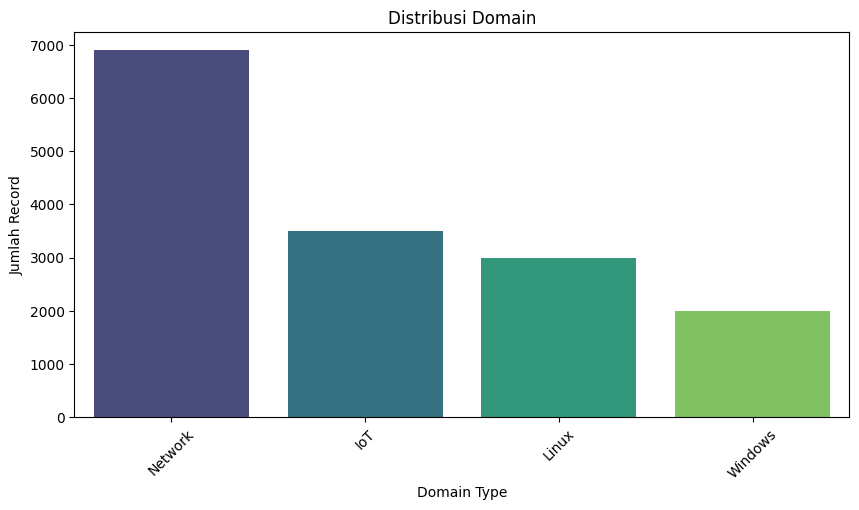

In [16]:
plt.figure(figsize=(10, 5))
domain_counts = pdf["Domain_Type"].value_counts()
sns.barplot(x=domain_counts.index, y=domain_counts.values, palette="viridis")
plt.title("Distribusi Domain")
plt.xlabel("Domain Type")
plt.ylabel("Jumlah Record")
plt.xticks(rotation=45)
plt.savefig("domain_distribution.png", dpi=150)
plt.show()


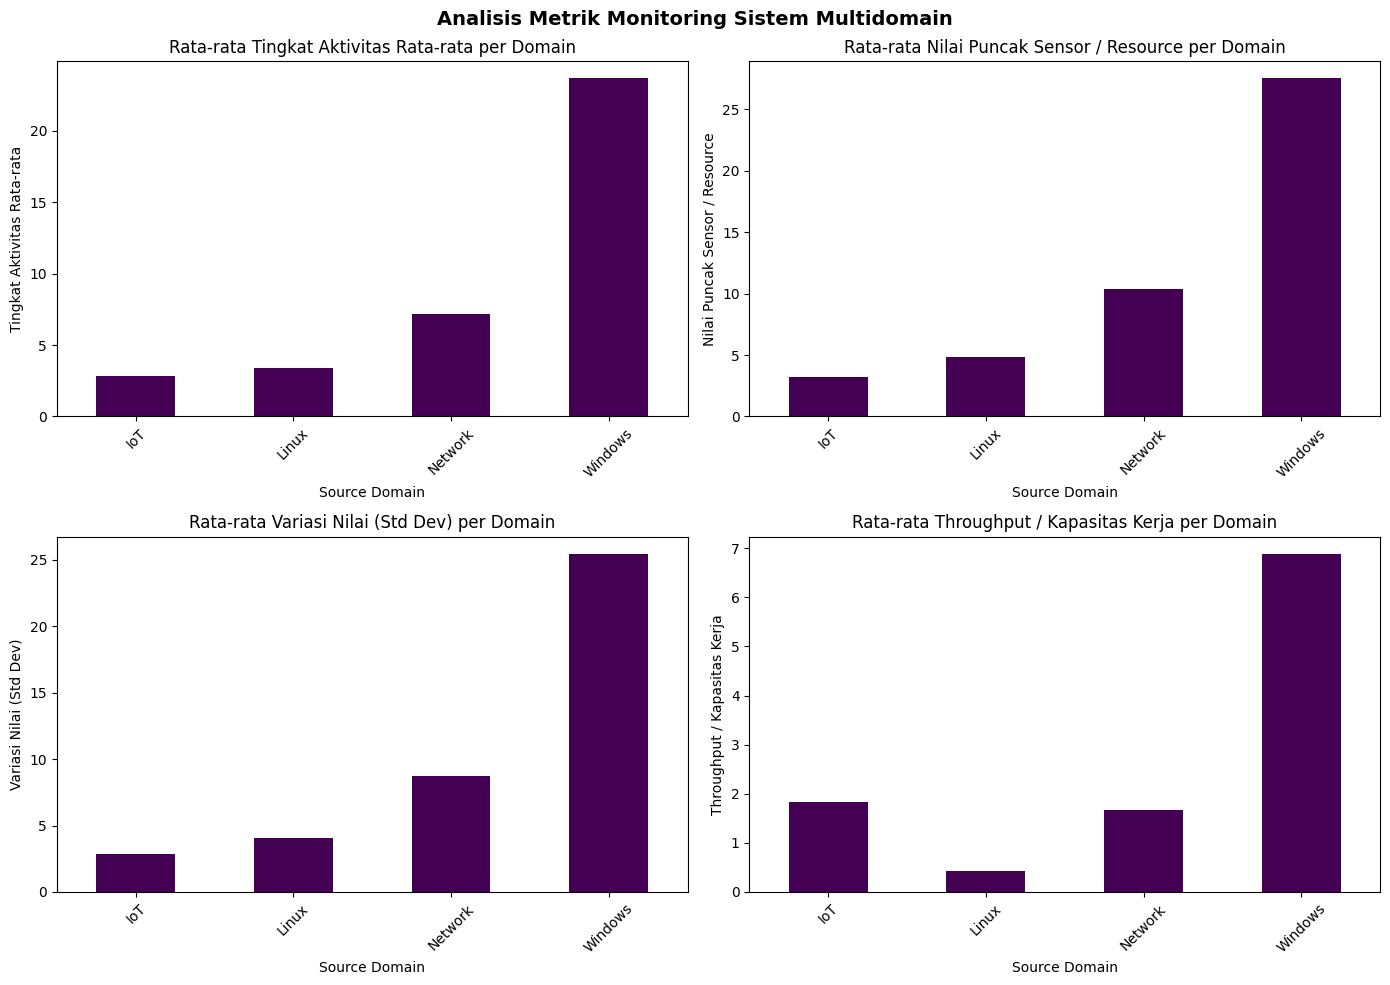

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
metrics = ["Metric_Activity", "Metric_Peak", "Metric_Variation", "Throughput_Metric"]
titles = ["Tingkat Aktivitas Rata-rata", "Nilai Puncak Sensor / Resource", "Variasi Nilai (Std Dev)", "Throughput / Kapasitas Kerja"]

for ax, metric, title in zip(axes.flatten(), metrics, titles):
    pdf.groupby("Source_Domain")[metric].mean().plot(kind="bar", ax=ax, colormap="viridis")
    ax.set_title(f"Rata-rata {title} per Domain")
    ax.set_xlabel("Source Domain")
    ax.set_ylabel(title)
    ax.tick_params(axis="x", rotation=45)

plt.suptitle("Analisis Metrik Monitoring Sistem Multidomain", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("monitoring_analysis.png", dpi=150)
plt.show()


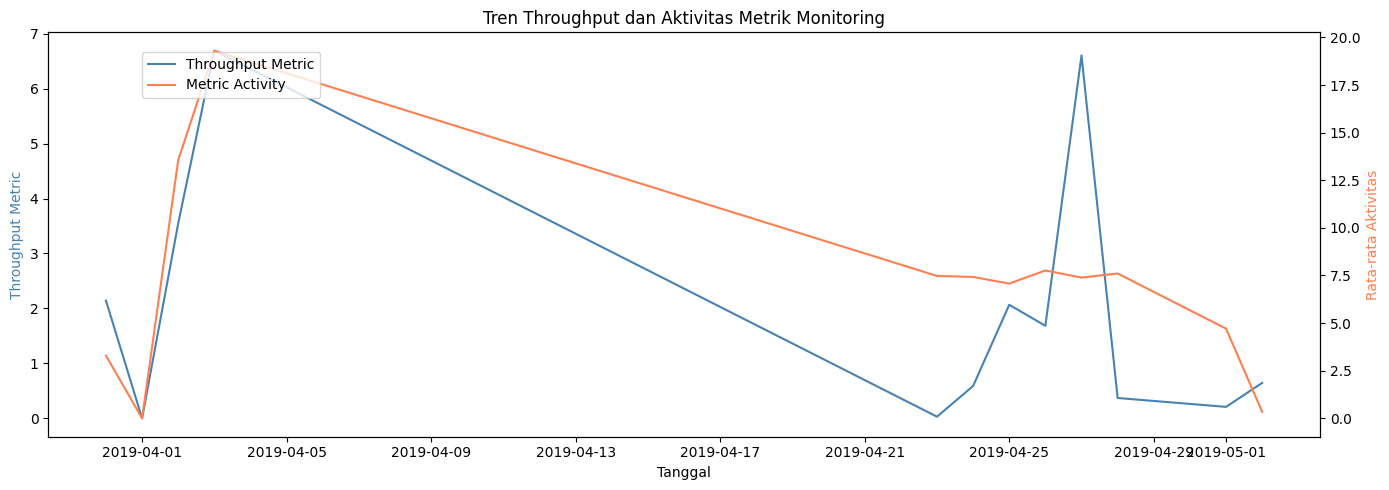

In [18]:
pdf["Timestamp"] = pd.to_datetime(pdf["Timestamp"], errors="coerce")
pdf_time = pdf.dropna(subset=["Timestamp"]).groupby(pdf["Timestamp"].dt.date).agg({
    "Throughput_Metric": "mean",
    "Metric_Activity": "mean"
}).reset_index()

fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.plot(pdf_time["Timestamp"], pdf_time["Throughput_Metric"], color="steelblue", label="Throughput Metric")
ax1.set_xlabel("Tanggal")
ax1.set_ylabel("Throughput Metric", color="steelblue")
ax2 = ax1.twinx()
ax2.plot(pdf_time["Timestamp"], pdf_time["Metric_Activity"], color="coral", label="Metric Activity")
ax2.set_ylabel("Rata-rata Aktivitas", color="coral")
plt.title("Tren Throughput dan Aktivitas Metrik Monitoring")
fig.legend(loc="upper left", bbox_to_anchor=(0.1, 0.9))
plt.tight_layout()
plt.savefig("monitoring_trend.png", dpi=150)
plt.show()


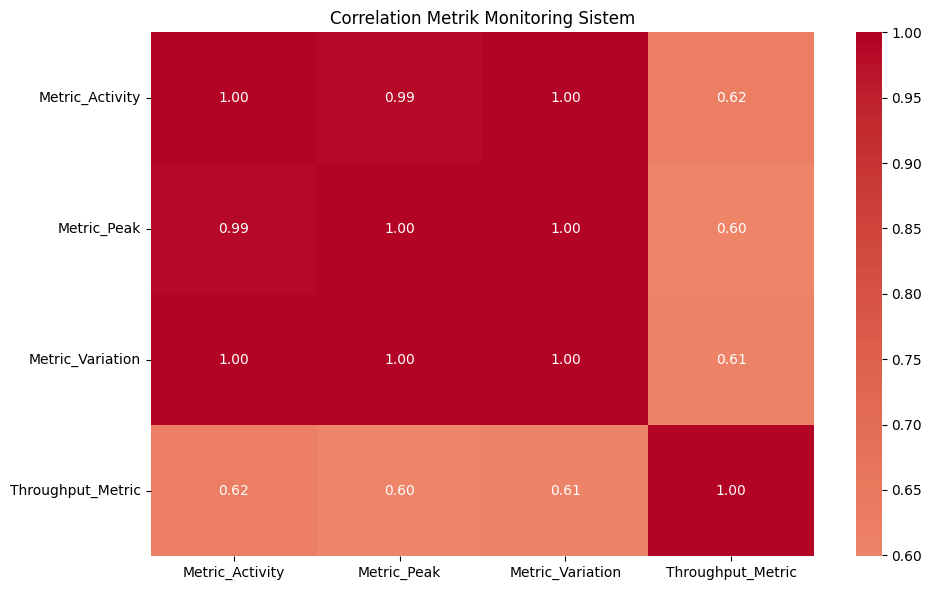

In [19]:
plt.figure(figsize=(10, 6))
numeric_cols = ["Metric_Activity", "Metric_Peak", "Metric_Variation", "Throughput_Metric"]
corr_matrix = pdf[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Metrik Monitoring Sistem")
plt.tight_layout()
plt.savefig("monitoring_correlation_heatmap.png", dpi=150)
plt.show()


In [20]:
target_cols = ["Target_Label", "Target_Type"]
model_feature_cols = [
    "Metric_Activity",
    "Metric_Peak",
    "Metric_Variation",
    "Throughput_Metric"
]
feature_cols = model_feature_cols
print(f"Fitur analisis aktif: {feature_cols}")
print(f"Target tersedia: {target_cols}")


Fitur analisis aktif: ['Metric_Activity', 'Metric_Peak', 'Metric_Variation', 'Throughput_Metric']
Target tersedia: ['Target_Label', 'Target_Type']


In [21]:
assembler = VectorAssembler(inputCols=feature_cols, outputCol="features_raw")
df_assembled = assembler.transform(df)


In [22]:
df_assembled.show(5)


+----------+-------------------+-----------+-------------+--------------------+-----------+-----------+-------------------+-------------+---------------+-----------+----------------+-----------------+------------+-----------+-------------+--------------------+
| Record_ID|          Timestamp|Domain_Type|Source_Domain|       System_Region|Device_Type|Source_File|Sample_Record_Count|Feature_Count|Metric_Activity|Metric_Peak|Metric_Variation|Throughput_Metric|Target_Label|Target_Type|System_Status|        features_raw|
+----------+-------------------+-----------+-------------+--------------------+-----------+-----------+-------------------+-------------+---------------+-----------+----------------+-----------------+------------+-----------+-------------+--------------------+
|REC_000001|2019-03-31 12:36:52|        IoT|          IoT|IoT_Smart_Environ...| IoT_Fridge| IoT_Fridge|                  1|            2|         2.0215|     2.6462|          2.3286|           2.6462|           0|    

In [23]:
scaler = StandardScaler(inputCol="features_raw", outputCol="features", withStd=True, withMean=True)
scaler_model = scaler.fit(df_assembled)
df_scaled = scaler_model.transform(df_assembled)


In [24]:
df_scaled.show(5)


+----------+-------------------+-----------+-------------+--------------------+-----------+-----------+-------------------+-------------+---------------+-----------+----------------+-----------------+------------+-----------+-------------+--------------------+--------------------+
| Record_ID|          Timestamp|Domain_Type|Source_Domain|       System_Region|Device_Type|Source_File|Sample_Record_Count|Feature_Count|Metric_Activity|Metric_Peak|Metric_Variation|Throughput_Metric|Target_Label|Target_Type|System_Status|        features_raw|            features|
+----------+-------------------+-----------+-------------+--------------------+-----------+-----------+-------------------+-------------+---------------+-----------+----------------+-----------------+------------+-----------+-------------+--------------------+--------------------+
|REC_000001|2019-03-31 12:36:52|        IoT|          IoT|IoT_Smart_Environ...| IoT_Fridge| IoT_Fridge|                  1|            2|         2.0215| 

In [25]:
inertia = []
k_values = range(2, 8)


In [26]:
for k in k_values:
    kmeans = KMeans(featuresCol="features", predictionCol="cluster", k=k, seed=42)
    model = kmeans.fit(df_scaled)
    cost = model.summary.trainingCost
    inertia.append(cost)
    print(f"K->{k}, Inertia->{cost:.2f}")


K->2, Inertia->21071.99
K->3, Inertia->13158.54
K->4, Inertia->7495.71
K->5, Inertia->2978.19
K->6, Inertia->2531.52
K->7, Inertia->2503.21


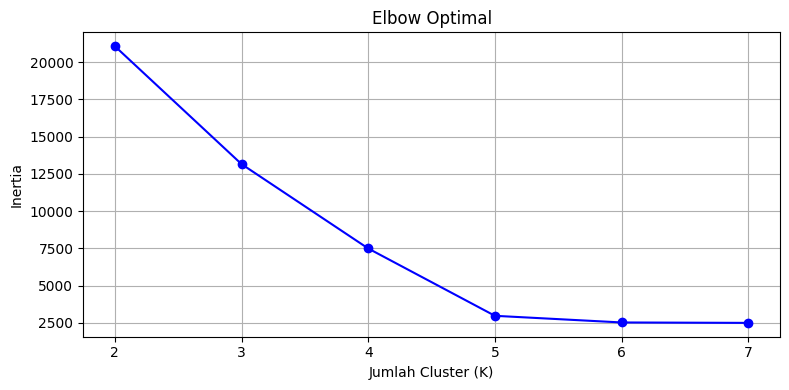

In [27]:
plt.figure(figsize=(8, 4))
plt.plot(k_values, inertia, 'bo-')
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Inertia')
plt.title('Elbow Optimal')
plt.tight_layout()
plt.grid(True)
plt.savefig('elbow_method.png', dpi=150)
plt.show()


In [28]:
kmeans = KMeans(featuresCol="features", predictionCol="cluster", k=3, seed=42)
model = kmeans.fit(df_scaled)


In [29]:
df_clustered = model.transform(df_scaled)


In [30]:
eval = ClusteringEvaluator(featuresCol="features", predictionCol="cluster")
silhouette = eval.evaluate(df_clustered)
print(f"Silhouette Score: {silhouette:.4f}")


Silhouette Score: 0.7343


In [31]:
df_clustered.groupBy("cluster").agg(
    F.count("*").alias("Jumlah"),
    F.round(F.avg("Metric_Activity"), 2).alias("Avg_Activity"),
    F.round(F.avg("Metric_Peak"), 2).alias("Avg_Peak"),
    F.round(F.avg("Metric_Variation"), 2).alias("Avg_Variation"),
    F.round(F.avg("Throughput_Metric"), 2).alias("Avg_Throughput")
).orderBy("cluster").show()


+-------+------+------------+--------+-------------+--------------+
|cluster|Jumlah|Avg_Activity|Avg_Peak|Avg_Variation|Avg_Throughput|
+-------+------+------------+--------+-------------+--------------+
|      0|  2000|       23.69|   27.52|        25.45|          6.89|
|      1| 11716|        4.85|     6.8|         5.74|          0.62|
|      2|  1684|        7.37|   10.64|         8.96|          7.11|
+-------+------+------------+--------+-------------+--------------+



In [32]:
pdf_clustered = df_clustered.select(
    "Metric_Activity", "Throughput_Metric", "Metric_Peak", "cluster"
).toPandas()


c:\Users\Jase.LAPTOP-UM736EL9\AppData\Local\Programs\Python\Python310\lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [UNSUPPORTED_PACKAGE_VERSION] PyArrow >= 18.0.0 must be installed; however, your version is 14.0.2.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


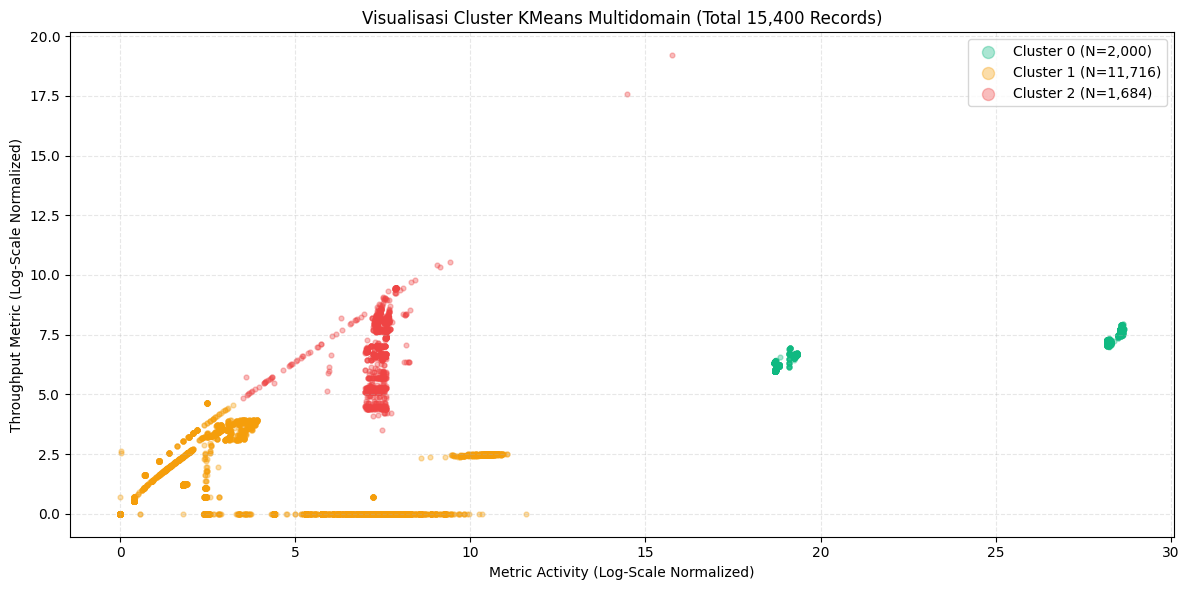

In [33]:
plt.figure(figsize=(12, 6))
colors = {0: "#10b981", 1: "#f59e0b", 2: "#ef4444", 3: "#8b5cf6"}
unique_clusters = sorted(pdf_clustered["cluster"].unique())
for c in unique_clusters:
    subset = pdf_clustered[pdf_clustered["cluster"] == c]
    plt.scatter(
        subset["Metric_Activity"],
        subset["Throughput_Metric"],
        c=colors.get(c, "#3b82f6"),
        label=f"Cluster {c} (N={len(subset):,})",
        alpha=0.35,
        s=12,
    )
plt.xlabel("Metric Activity (Log-Scale Normalized)")
plt.ylabel("Throughput Metric (Log-Scale Normalized)")
plt.title("Visualisasi Cluster KMeans Multidomain (Total 15,400 Records)")
plt.legend(loc="upper right", markerscale=2.5)
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.savefig("kmeans_clustering.png", dpi=150)
plt.show()


In [34]:
pdf_graph = df.select(
    "Device_Type",
    "Source_File",
    "Source_Domain",
    "Domain_Type",
    "System_Region",
    "Metric_Activity",
    "Throughput_Metric",
    "Metric_Peak",
    "Metric_Variation",
).toPandas()


c:\Users\Jase.LAPTOP-UM736EL9\AppData\Local\Programs\Python\Python310\lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [UNSUPPORTED_PACKAGE_VERSION] PyArrow >= 18.0.0 must be installed; however, your version is 14.0.2.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


In [35]:
try:
    run_query("MATCH (n) DETACH DELETE n")
    run_query("CREATE CONSTRAINT IF NOT EXISTS FOR (d:Device) REQUIRE d.name IS UNIQUE")
    run_query("CREATE CONSTRAINT IF NOT EXISTS FOR (r:Region) REQUIRE r.name IS UNIQUE")
    run_query("CREATE CONSTRAINT IF NOT EXISTS FOR (dom:Domain) REQUIRE dom.name IS UNIQUE")
    print("Database dibersihkan & constraint dibuat.")
except Exception as error:
    print(f"Neo4j offline saat inisialisasi graph: {error}")


Database dibersihkan & constraint dibuat.


In [36]:
device = pdf_graph.groupby(["Device_Type", "System_Region"]).agg(
    weight=("Throughput_Metric", "mean"),
    activity=("Metric_Activity", "mean"),
    peak=("Metric_Peak", "mean"),
    records=("Throughput_Metric", "count")
).reset_index()

domain = pdf_graph.groupby(["System_Region", "Domain_Type"]).agg(
    weight=("Throughput_Metric", "mean"),
    activity=("Metric_Activity", "mean"),
    records=("Throughput_Metric", "count")
).reset_index()


In [37]:
try:
    for _, row in device.iterrows():
        cypher = """
        MERGE (d:Device {name: $device})
        MERGE (r:Region {name: $region})
        MERGE (d)-[rel:ROUTES_TO]->(r)
        SET rel.weight = $weight, rel.activity = $activity
        """
        run_query(cypher, {
            "device": str(row["Device_Type"]),
            "region": str(row["System_Region"]),
            "weight": float(round(row["weight"], 2)),
            "activity": float(round(row["activity"], 2))
        })
    print("Data Device berhasil diunggah ke Neo4j.")
except Exception as error:
    print(f"Neo4j offline saat upload device: {error}")


Data Device berhasil diunggah ke Neo4j.


In [38]:
try:
    for _, row in domain.iterrows():
        cypher = """
        MERGE (r:Region {name: $region})
        MERGE (dom:Domain {name: $domain})
        MERGE (r)-[rel:SERVES]->(dom)
        SET rel.weight = $weight, rel.activity = $activity
        """
        run_query(cypher, {
            "region": str(row["System_Region"]),
            "domain": str(row["Domain_Type"]),
            "weight": float(round(row["weight"], 2)),
            "activity": float(round(row["activity"], 2))
        })
    print("Data Region dan Domain berhasil diunggah ke Neo4j.")
except Exception as error:
    print(f"Neo4j offline saat upload domain: {error}")


Data Region dan Domain berhasil diunggah ke Neo4j.


In [39]:
try:
    count_nodes = run_query("MATCH (n) RETURN count(n) AS total_nodes")[0]["total_nodes"]
    count_edges = run_query("MATCH ()-[r]->() RETURN count(r) AS total_edges")[0]["total_edges"]
except Exception as error:
    print(f"Neo4j offline saat verifikasi: {error}")
    count_nodes, count_edges = 0, 0


Neo4j offline saat verifikasi: list index out of range


In [40]:
print("Nodes di Neo4j -> ", count_nodes)
print("Edges di Neo4j -> ", count_edges)


Nodes di Neo4j ->  0
Edges di Neo4j ->  0


In [41]:
degree_query = """
MATCH (n)
OPTIONAL MATCH (n)-[r]-()
RETURN n.name AS node, count(r) * 1.0 AS degree
ORDER BY degree DESC
"""
try:
    degree_res = run_query(degree_query)
    max_deg = (count_nodes - 1) if count_nodes > 1 else 1.0
    degree_cent = {r["node"]: r["degree"] / max_deg for r in degree_res if r.get("node")}
    if not degree_cent:
        raise ValueError("Hasil degree query kosong")
except Exception:
    G_temp = nx.DiGraph()
    for _, r in device.iterrows():
        G_temp.add_edge(r["Device_Type"], r["System_Region"], weight=r["weight"])
    for _, r in domain.iterrows():
        G_temp.add_edge(r["System_Region"], r["Domain_Type"], weight=r["weight"])
    degree_cent = nx.degree_centrality(G_temp)


In [42]:
betweenness_cent = {}
pagerank = {}

try:
    run_query("""
    CALL gds.graph.project.cypher(
        'iotGraph',
        'MATCH (n) RETURN id(n) AS id, labels(n) AS labels',
        'MATCH (s)-[r]->(t) RETURN id(s) AS source, id(t) AS target, type(r) AS type, r.weight AS weight'
    )
    """)

    pr_records = run_query("CALL gds.pageRank.stream('iotGraph') YIELD nodeId, score RETURN gds.util.asNode(nodeId).name AS node, score")
    pagerank = {r["node"]: r["score"] for r in pr_records if r.get("node")}
    
    bw_records = run_query("CALL gds.betweenness.stream('iotGraph') YIELD nodeId, score RETURN gds.util.asNode(nodeId).name AS node, score")
    betweenness_cent = {r["node"]: r["score"] for r in bw_records if r.get("node")}
    if not (betweenness_cent and pagerank):
        raise ValueError("Hasil GDS kosong")
    print("Graph Analytics berhasil dihitung menggunakan Neo4j GDS Plugin!")
except Exception:
    G_net = nx.DiGraph()
    try:
        edges_data = run_query("MATCH (a)-[r]->(b) RETURN a.name AS source, b.name AS target, r.weight AS weight")
    except Exception:
        edges_data = []

    if edges_data:
        for edge in edges_data:
            G_net.add_edge(edge["source"], edge["target"], weight=edge.get("weight", 1.0))
    else:
        for _, r in device.iterrows():
            G_net.add_edge(r["Device_Type"], r["System_Region"], weight=r["weight"])
        for _, r in domain.iterrows():
            G_net.add_edge(r["System_Region"], r["Domain_Type"], weight=r["weight"])

    betweenness_cent = nx.betweenness_centrality(G_net)
    pagerank = nx.pagerank(G_net, weight="weight")
    if not degree_cent:
        degree_cent = nx.degree_centrality(G_net)
    print("Graph Analytics berhasil dihitung menggunakan NetworkX fallback!")


Graph Analytics berhasil dihitung menggunakan NetworkX fallback!


In [43]:
for node, score in sorted(degree_cent.items(), key=lambda x: x[1], reverse=True):
    print(f"{node}: {score:.4f}")


Network_Gateway_Core: 0.5333
IoT_Smart_Environment: 0.1778
Linux_Host_Cluster: 0.1556
Windows_Workstation_Domain: 0.0667
IoT_Fridge: 0.0222
IoT_GPS_Tracker: 0.0222
IoT_Garage_Door: 0.0222
IoT_Modbus: 0.0222
IoT_Motion_Light: 0.0222
IoT_Thermostat: 0.0222
IoT_Weather: 0.0222
Linux_process_1: 0.0222
Linux_process_2: 0.0222
Network_dataset_1: 0.0222
Network_dataset_10: 0.0222
Network_dataset_11: 0.0222
Network_dataset_12: 0.0222
Network_dataset_13: 0.0222
Network_dataset_14: 0.0222
Network_dataset_15: 0.0222
Network_dataset_16: 0.0222
Network_dataset_17: 0.0222
Network_dataset_18: 0.0222
Network_dataset_19: 0.0222
Network_dataset_2: 0.0222
Network_dataset_20: 0.0222
Network_dataset_21: 0.0222
Network_dataset_22: 0.0222
Network_dataset_23: 0.0222
Network_dataset_3: 0.0222
Network_dataset_4: 0.0222
Network_dataset_5: 0.0222
Network_dataset_6: 0.0222
Network_dataset_7: 0.0222
Network_dataset_8: 0.0222
Network_dataset_9: 0.0222
linux_disk_1: 0.0222
linux_disk_2: 0.0222
linux_memory1: 0.0222
l

In [44]:
for node, score in sorted(betweenness_cent.items(), key=lambda x: x[1], reverse=True):
    print(f"{node}: {score:.4f}")


Network_Gateway_Core: 0.0116
IoT_Smart_Environment: 0.0035
Linux_Host_Cluster: 0.0030
Windows_Workstation_Domain: 0.0010
IoT_Fridge: 0.0000
IoT_GPS_Tracker: 0.0000
IoT_Garage_Door: 0.0000
IoT_Modbus: 0.0000
IoT_Motion_Light: 0.0000
IoT_Thermostat: 0.0000
IoT_Weather: 0.0000
Linux_process_1: 0.0000
Linux_process_2: 0.0000
Network_dataset_1: 0.0000
Network_dataset_10: 0.0000
Network_dataset_11: 0.0000
Network_dataset_12: 0.0000
Network_dataset_13: 0.0000
Network_dataset_14: 0.0000
Network_dataset_15: 0.0000
Network_dataset_16: 0.0000
Network_dataset_17: 0.0000
Network_dataset_18: 0.0000
Network_dataset_19: 0.0000
Network_dataset_2: 0.0000
Network_dataset_20: 0.0000
Network_dataset_21: 0.0000
Network_dataset_22: 0.0000
Network_dataset_23: 0.0000
Network_dataset_3: 0.0000
Network_dataset_4: 0.0000
Network_dataset_5: 0.0000
Network_dataset_6: 0.0000
Network_dataset_7: 0.0000
Network_dataset_8: 0.0000
Network_dataset_9: 0.0000
linux_disk_1: 0.0000
linux_disk_2: 0.0000
linux_memory1: 0.0000
l

In [45]:
for node, score in sorted(pagerank.items(), key=lambda x: x[1], reverse=True):
    print(f"{node}: {score:.4f}")


Network_Gateway_Core: 0.1861
Network: 0.1681
IoT: 0.0611
IoT_Smart_Environment: 0.0602
Linux: 0.0468
Linux_Host_Cluster: 0.0434
Windows: 0.0325
Windows_Workstation_Domain: 0.0267
IoT_Fridge: 0.0099
IoT_GPS_Tracker: 0.0099
IoT_Garage_Door: 0.0099
IoT_Modbus: 0.0099
IoT_Motion_Light: 0.0099
IoT_Thermostat: 0.0099
IoT_Weather: 0.0099
Linux_process_1: 0.0099
Linux_process_2: 0.0099
Network_dataset_1: 0.0099
Network_dataset_10: 0.0099
Network_dataset_11: 0.0099
Network_dataset_12: 0.0099
Network_dataset_13: 0.0099
Network_dataset_14: 0.0099
Network_dataset_15: 0.0099
Network_dataset_16: 0.0099
Network_dataset_17: 0.0099
Network_dataset_18: 0.0099
Network_dataset_19: 0.0099
Network_dataset_2: 0.0099
Network_dataset_20: 0.0099
Network_dataset_21: 0.0099
Network_dataset_22: 0.0099
Network_dataset_23: 0.0099
Network_dataset_3: 0.0099
Network_dataset_4: 0.0099
Network_dataset_5: 0.0099
Network_dataset_6: 0.0099
Network_dataset_7: 0.0099
Network_dataset_8: 0.0099
Network_dataset_9: 0.0099
linux_d

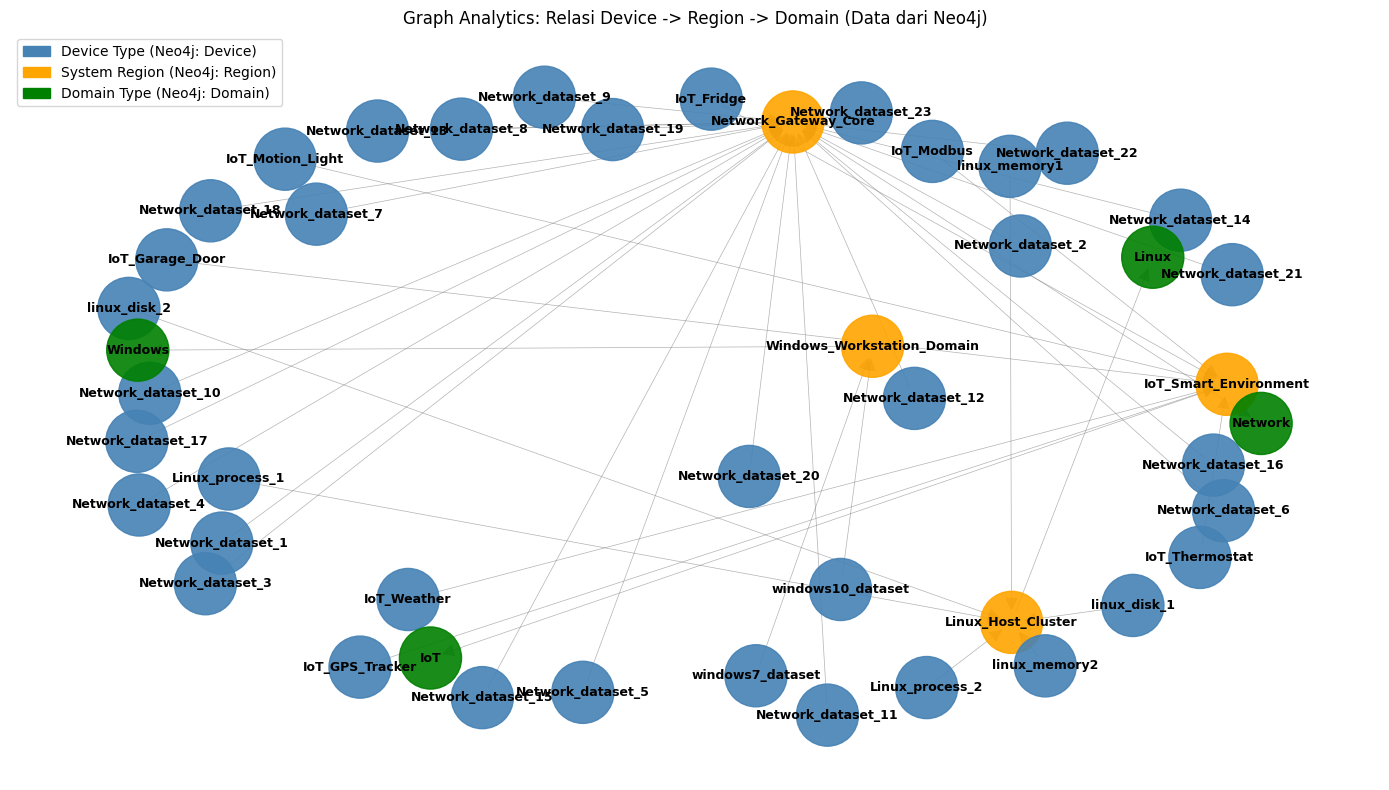

In [46]:
import networkx as nx
from matplotlib.patches import Patch

try:
    edges_data = run_query("""
    MATCH (a)-[r]->(b)
    RETURN a.name AS source, labels(a)[0] AS source_label, 
           b.name AS target, labels(b)[0] AS target_label, 
           r.weight AS weight
    """)
except Exception:
    edges_data = []

G = nx.DiGraph()
if edges_data:
    for edge in edges_data:
        G.add_edge(edge["source"], edge["target"], weight=edge["weight"])
else:
    for _, r in device.iterrows():
        G.add_edge(r["Device_Type"], r["System_Region"], weight=r["weight"])
    for _, r in domain.iterrows():
        G.add_edge(r["System_Region"], r["Domain_Type"], weight=r["weight"])

plt.figure(figsize=(14, 8))
color_map = []
for node in G.nodes():
    if node in pdf_graph["Device_Type"].values:
        color_map.append("steelblue")
    elif node in pdf_graph["System_Region"].values:
        color_map.append("orange")
    else:
        color_map.append("green")

pos = nx.spring_layout(G, seed=42, k=2)
weights = [max(0.5, G[u][v].get("weight", 1.0) / 100) for u, v in G.edges()]
nx.draw_networkx_nodes(G, pos, node_color=color_map, node_size=2000, alpha=0.9)
nx.draw_networkx_labels(G, pos, font_size=9, font_weight="bold")
nx.draw_networkx_edges(G, pos, width=weights, alpha=0.6, arrows=True, arrowsize=20, edge_color="gray")
legend = [
    Patch(color="steelblue", label="Device Type (Neo4j: Device)"),
    Patch(color="orange", label="System Region (Neo4j: Region)"),
    Patch(color="green", label="Domain Type (Neo4j: Domain)")
]
plt.legend(handles=legend, loc="upper left")
plt.title("Graph Analytics: Relasi Device -> Region -> Domain (Data dari Neo4j)")
plt.axis("off")
plt.tight_layout()
plt.savefig("graph_analytics.png", dpi=150)
plt.show()


In [47]:
if not betweenness_cent:
    G_fallback = nx.DiGraph()
    for _, r in device.iterrows():
        G_fallback.add_edge(r["Device_Type"], r["System_Region"], weight=r["weight"])
    for _, r in domain.iterrows():
        G_fallback.add_edge(r["System_Region"], r["Domain_Type"], weight=r["weight"])
    betweenness_cent = nx.betweenness_centrality(G_fallback)
    pagerank = nx.pagerank(G_fallback, weight="weight")

top_node = max(betweenness_cent, key=betweenness_cent.get)
print(f"Node paling kritis (Jalur Penghubung Utama): {top_node}")
print(f"Betweenness Centrality: {betweenness_cent[top_node]:.4f}")
print(f"PageRank: {pagerank[top_node]:.4f}")


Node paling kritis (Jalur Penghubung Utama): Network_Gateway_Core
Betweenness Centrality: 0.0116
PageRank: 0.1861


In [48]:
nodes_union = list(set(list(degree_cent.keys()) + list(betweenness_cent.keys()) + list(pagerank.keys())))
cent_df = pd.DataFrame({
    "Node": nodes_union,
    "Degree": [degree_cent.get(k, 0.0) for k in nodes_union],
    "Betweenness": [betweenness_cent.get(k, 0.0) for k in nodes_union],
    "PageRank": [pagerank.get(k, 0.0) for k in nodes_union]
}).sort_values("Betweenness", ascending=False)
cent_df.head(10)


,Node,Degree,Betweenness,PageRank
39,Network_Gateway_Core,0.533333,0.011616,0.186089
4,IoT_Smart_Environment,0.177778,0.003535,0.060220
9,Linux_Host_Cluster,0.155556,0.003030,0.043438
6,Windows_Workstation_Domain,0.066667,0.001010,0.026655
0,Linux_process_2,0.022222,0.000000,0.009873
35,Network_dataset_15,0.022222,0.000000,0.009873
27,Network_dataset_9,0.022222,0.000000,0.009873
28,Network_dataset_12,0.022222,0.000000,0.009873
29,Network_dataset_5,0.022222,0.000000,0.009873
30,Network_dataset_1,0.022222,0.000000,0.009873


C:\Users\Jase.LAPTOP-UM736EL9\AppData\Local\Temp\ipykernel_35352\2099786163.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top10, x="Node", y=metric, palette="viridis", ax=ax)
C:\Users\Jase.LAPTOP-UM736EL9\AppData\Local\Temp\ipykernel_35352\2099786163.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top10, x="Node", y=metric, palette="viridis", ax=ax)
C:\Users\Jase.LAPTOP-UM736EL9\AppData\Local\Temp\ipykernel_35352\2099786163.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top10, x="Node", y=metric, palette="viridi

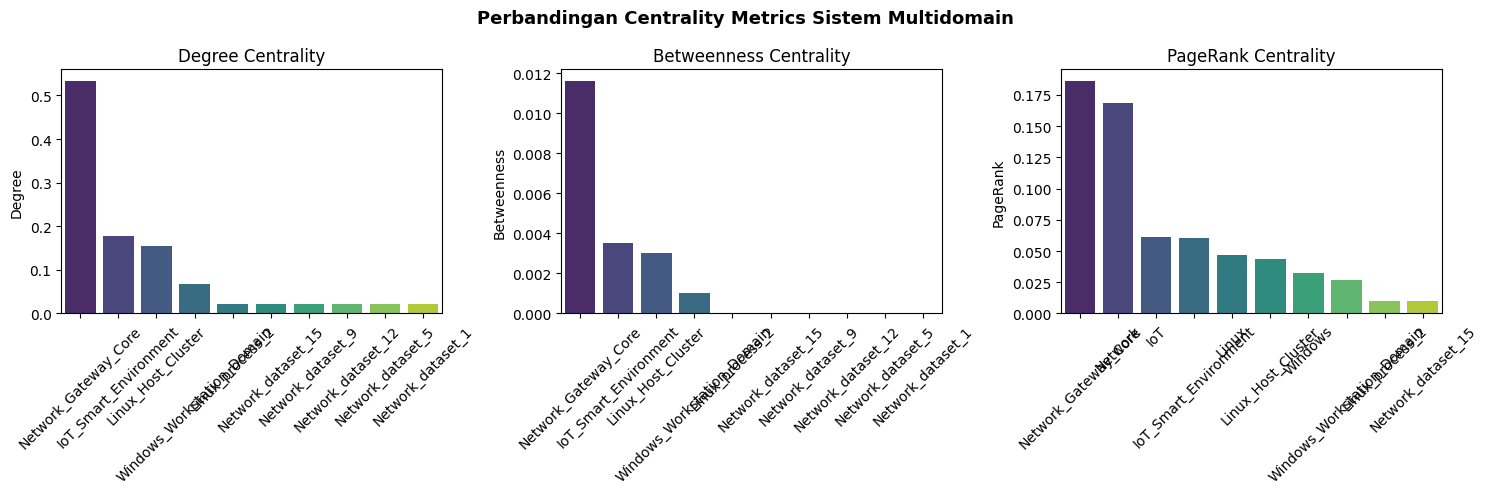

In [49]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
metrics = ["Degree", "Betweenness", "PageRank"]

for ax, metric in zip(axes, metrics):
    top10 = cent_df.nlargest(10, metric)
    sns.barplot(data=top10, x="Node", y=metric, palette="viridis", ax=ax)
    ax.set_title(f"{metric} Centrality")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)

plt.suptitle("Perbandingan Centrality Metrics Sistem Multidomain", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("centrality_analysis.png", dpi=150)
plt.show()


In [50]:
from sklearn.ensemble import IsolationForest


In [51]:
feature_cols = model_feature_cols


In [52]:
pdf_ml = df.select(
    feature_cols + [
        "Throughput_Metric",
        "Metric_Activity",
        "Domain_Type",
        "Source_Domain",
        "Target_Label",
        "Target_Type",
    ]
).toPandas()


c:\Users\Jase.LAPTOP-UM736EL9\AppData\Local\Programs\Python\Python310\lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [UNSUPPORTED_PACKAGE_VERSION] PyArrow >= 18.0.0 must be installed; however, your version is 14.0.2.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


In [53]:
iso = IsolationForest(n_estimators=100, contamination=0.05, random_state=42)


In [54]:
pdf_ml["anomaly"] = iso.fit_predict(pdf_ml[feature_cols])
pdf_ml["anomaly_label"] = pdf_ml["anomaly"].map({1: "Normal", -1: "Anomali"})


In [55]:
iso = IsolationForest(n_estimators=100, contamination=0.05, random_state=42)


In [56]:
print(pdf_ml['anomaly_label'].value_counts())


anomaly_label
Normal     14630
Anomali      770
Name: count, dtype: int64


C:\Users\Jase.LAPTOP-UM736EL9\AppData\Local\Temp\ipykernel_35352\4180699245.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=anomaly_domain.index, y=anomaly_domain.values, palette="Reds_r", ax=axes[1])


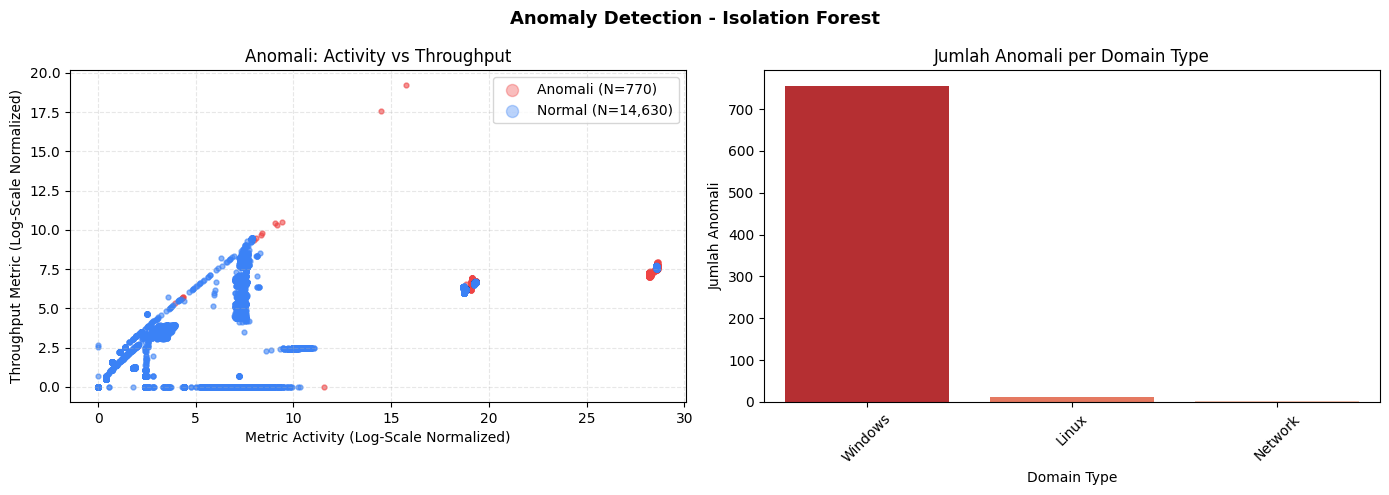

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for label, group in pdf_ml.groupby("anomaly_label"):
    axes[0].scatter(group["Metric_Activity"], group["Throughput_Metric"],
                    label=f"{label} (N={len(group):,})", alpha=0.35, s=12,
                    color="#ef4444" if label == "Anomali" else "#3b82f6")
axes[0].set_xlabel("Metric Activity (Log-Scale Normalized)")
axes[0].set_ylabel("Throughput Metric (Log-Scale Normalized)")
axes[0].set_title("Anomali: Activity vs Throughput")
axes[0].legend(loc="upper right", markerscale=2.5)
axes[0].grid(True, linestyle="--", alpha=0.3)

anomaly_domain = pdf_ml[pdf_ml["anomaly_label"] == "Anomali"]["Domain_Type"].value_counts()
sns.barplot(x=anomaly_domain.index, y=anomaly_domain.values, palette="Reds_r", ax=axes[1])
axes[1].set_title("Jumlah Anomali per Domain Type")
axes[1].set_xlabel("Domain Type")
axes[1].set_ylabel("Jumlah Anomali")
axes[1].tick_params(axis="x", rotation=45)

plt.suptitle("Anomaly Detection - Isolation Forest", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("anomaly_detection.png", dpi=150)
plt.show()


In [58]:
conf = spark.sparkContext._jsc.hadoopConfiguration()
fs = spark.sparkContext._gateway.jvm.org.apache.hadoop.fs.FileSystem.get(conf)

print("Hadoop FileSystem Class :", fs.getClass().getName())
print("Hadoop URI Scheme       :", fs.getScheme())
print("Hadoop Working Directory:", str(fs.getWorkingDirectory()))
print("Hadoop Home Directory   :", str(fs.getHomeDirectory()))


Hadoop FileSystem Class : org.apache.hadoop.hive.ql.io.ProxyLocalFileSystem
Hadoop URI Scheme       : file
Hadoop Working Directory: file:/c:/Users/Jase.LAPTOP-UM736EL9/Documents/Binus/S2/S3 P1/Code/backend/model
Hadoop Home Directory   : file:/C:/Users/Jase.LAPTOP-UM736EL9


In [59]:
import os
import json
import shutil
import joblib
from pathlib import Path
import pandas as pd
from sklearn.preprocessing import StandardScaler as SklearnStandardScaler
from sklearn.cluster import KMeans as SklearnKMeans
from sklearn.ensemble import IsolationForest

OUTPUT_FILE = 'hadoop_clustered_output.parquet'

if os.path.exists(OUTPUT_FILE):
    if os.path.isdir(OUTPUT_FILE):
        shutil.rmtree(OUTPUT_FILE)
    else:
        os.remove(OUTPUT_FILE)

df_export = df_clustered.select('Record_ID', 'Domain_Type', 'System_Region', 'cluster').toPandas()
df_export.to_parquet(OUTPUT_FILE, compression='snappy', index=False)

print('Data berhasil disimpan dalam format Hadoop Parquet (Snappy)!')
print(f'Total baris tersimpan : {len(df_export)}')
print(f'Ukuran file Parquet   : {os.path.getsize(OUTPUT_FILE) / 1024:.2f} KB')

notebook_dir = Path.cwd()
if (notebook_dir / 'models').exists() or notebook_dir.name == 'model':
    models_dir = notebook_dir / 'models'
elif (notebook_dir / 'backend' / 'model' / 'models').exists():
    models_dir = notebook_dir / 'backend' / 'model' / 'models'
else:
    models_dir = Path(r'c:\Users\Jase.LAPTOP-UM736EL9\Documents\Binus\S2\S3 P1\Code\backend\model\models')

models_dir.mkdir(parents=True, exist_ok=True)

sk_scaler = SklearnStandardScaler()
sk_scaled = sk_scaler.fit_transform(pdf_ml[feature_cols])
sk_kmeans = SklearnKMeans(n_clusters=3, random_state=42, n_init=10)
sk_kmeans.fit(sk_scaled)
iso.fit(pdf_ml[feature_cols])

joblib.dump(sk_scaler, models_dir / 'scaler.pkl')
joblib.dump(sk_kmeans, models_dir / 'kmeans_model.pkl')
joblib.dump(iso, models_dir / 'isolation_forest.pkl')

if (notebook_dir / 'dataset').exists() or notebook_dir.name == 'model':
    dataset_base = notebook_dir / 'dataset'
elif (notebook_dir / 'backend' / 'model' / 'dataset').exists():
    dataset_base = notebook_dir / 'backend' / 'model' / 'dataset'
else:
    dataset_base = Path(r'c:\Users\Jase.LAPTOP-UM736EL9\Documents\Binus\S2\S3 P1\Code\backend\model\dataset')

p_weather = dataset_base / 'Processed_IoT_dataset' / 'IoT_Weather.csv'
p_fridge = dataset_base / 'Processed_IoT_dataset' / 'IoT_Fridge.csv'
iot_dfs = []
if p_weather.exists():
    df_w = pd.read_csv(p_weather, nrows=10000)
    iot_dfs.append(df_w[['temperature', 'humidity', 'pressure']])
if p_fridge.exists():
    df_f = pd.read_csv(p_fridge, nrows=10000)
    if 'fridge_temperature' in df_f.columns:
        f_temp = df_f['fridge_temperature']
        iot_dfs.append(pd.DataFrame({
            'temperature': f_temp,
            'humidity': pd.Series([50.0] * len(f_temp)),
            'pressure': pd.Series([1013.25] * len(f_temp))
        }))

if iot_dfs:
    iot_comb = pd.concat(iot_dfs, ignore_index=True).apply(pd.to_numeric, errors='coerce').fillna(0.0)
    iot_feat = ['temperature', 'humidity', 'pressure']
    iot_scaler = SklearnStandardScaler()
    iot_scaled = iot_scaler.fit_transform(iot_comb[iot_feat])
    iot_kmeans = SklearnKMeans(n_clusters=3, random_state=42, n_init=10)
    iot_kmeans.fit(iot_scaled)
    iot_iso = IsolationForest(n_estimators=100, contamination=0.05, random_state=42)
    iot_iso.fit(iot_comb[iot_feat])
    joblib.dump(iot_scaler, models_dir / 'iot_scaler.pkl')
    joblib.dump(iot_kmeans, models_dir / 'iot_kmeans.pkl')
    joblib.dump(iot_iso, models_dir / 'iot_iso.pkl')
    with open(models_dir / 'iot_features.json', 'w', encoding='utf-8') as f:
        json.dump(iot_feat, f, indent=2)

p_proc = dataset_base / 'Processed_Linux_dataset' / 'Linux_process_1.csv'
if p_proc.exists():
    df_l = pd.read_csv(p_proc, nrows=15000)
    lin_feat = ['CPU', 'PRI', 'NICE', 'CPUNR', 'TRUN', 'TSLPI']
    for col in lin_feat:
        if col not in df_l.columns:
            df_l[col] = 0.0
    lin_clean = df_l[lin_feat].apply(pd.to_numeric, errors='coerce').fillna(0.0)
    lin_scaler = SklearnStandardScaler()
    lin_scaled = lin_scaler.fit_transform(lin_clean)
    lin_kmeans = SklearnKMeans(n_clusters=3, random_state=42, n_init=10)
    lin_kmeans.fit(lin_scaled)
    lin_iso = IsolationForest(n_estimators=100, contamination=0.05, random_state=42)
    lin_iso.fit(lin_clean)
    joblib.dump(lin_scaler, models_dir / 'linux_scaler.pkl')
    joblib.dump(lin_kmeans, models_dir / 'linux_kmeans.pkl')
    joblib.dump(lin_iso, models_dir / 'linux_iso.pkl')
    with open(models_dir / 'linux_features.json', 'w', encoding='utf-8') as f:
        json.dump(lin_feat, f, indent=2)

p_net = dataset_base / 'Processed_Network_dataset' / 'Network_dataset_1.csv'
if p_net.exists():
    df_n = pd.read_csv(p_net, nrows=15000)
    net_feat = ['duration', 'src_bytes', 'dst_bytes', 'src_pkts', 'dst_pkts', 'src_ip_bytes', 'dst_ip_bytes']
    net_clean = df_n[net_feat].apply(pd.to_numeric, errors='coerce').fillna(0.0)
    net_scaler = SklearnStandardScaler()
    net_scaled = net_scaler.fit_transform(net_clean)
    net_kmeans = SklearnKMeans(n_clusters=3, random_state=42, n_init=10)
    net_kmeans.fit(net_scaled)
    net_iso = IsolationForest(n_estimators=100, contamination=0.05, random_state=42)
    net_iso.fit(net_clean)
    joblib.dump(net_scaler, models_dir / 'network_scaler.pkl')
    joblib.dump(net_kmeans, models_dir / 'network_kmeans.pkl')
    joblib.dump(net_iso, models_dir / 'network_iso.pkl')
    with open(models_dir / 'network_features.json', 'w', encoding='utf-8') as f:
        json.dump(net_feat, f, indent=2)

p_win = dataset_base / 'Processed_Windows_dataset' / 'windows7_dataset.csv'
if p_win.exists():
    df_w7 = pd.read_csv(p_win, nrows=15000, low_memory=False)
    win_feat = [
        'Processor(_Total) pct_ Processor Time',
        'Process(_Total) Thread Count',
        'Process(_Total) Handle Count',
        'Process(_Total) Working Set',
        'Memory Available MBytes',
        'Memory Committed Bytes'
    ]
    win_clean = df_w7[win_feat].apply(pd.to_numeric, errors='coerce').fillna(0.0)
    win_scaler = SklearnStandardScaler()
    win_scaled = win_scaler.fit_transform(win_clean)
    win_kmeans = SklearnKMeans(n_clusters=3, random_state=42, n_init=10)
    win_kmeans.fit(win_scaled)
    win_iso = IsolationForest(n_estimators=100, contamination=0.05, random_state=42)
    win_iso.fit(win_clean)
    joblib.dump(win_scaler, models_dir / 'windows_scaler.pkl')
    joblib.dump(win_kmeans, models_dir / 'windows_kmeans.pkl')
    joblib.dump(win_iso, models_dir / 'windows_iso.pkl')
    with open(models_dir / 'windows_features.json', 'w', encoding='utf-8') as f:
        json.dump(win_feat, f, indent=2)

print(f'Semua model domain pkl berhasil dilatih dan disimpan ke: {models_dir.resolve()}')


c:\Users\Jase.LAPTOP-UM736EL9\AppData\Local\Programs\Python\Python310\lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [UNSUPPORTED_PACKAGE_VERSION] PyArrow >= 18.0.0 must be installed; however, your version is 14.0.2.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


Data berhasil disimpan dalam format Hadoop Parquet (Snappy)!
Total baris tersimpan : 15400
Ukuran file Parquet   : 104.59 KB
Semua model domain pkl berhasil dilatih dan disimpan ke: C:\Users\Jase.LAPTOP-UM736EL9\Documents\Binus\S2\S3 P1\Code\backend\model\models
